# Практичне завдання 2: Логiстична регресiя та федеративне навчання
### Мета завдання:
Зрозумiти архiтектуру багатокласової логiстичної регресiї, навчитися самостiйно реалiзовувати модель засобами numpy, зрозумiти принципи федеративного навчання, правильно розподiлити данi мiж клiєнтами та сервером, реалiзувати агрегацiю ваг та проаналiзувати базовi ефекти розподiленого навчання.
`Датасет:` Dry Bean Dataset

In [4]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


### Етап 1. Дослiдження даних та попередня обробка
1. **Первинний аналiз даних:**
 структура датасету та типи ознак;
 пропущенi значення;
 розподiл цiльової змiнної;
 основнi статистики числових ознак;
 кореляцiї мiж ознаками.
2. **Вiдбiр ознак:**
 визначити, якi ознаки доцiльно використовувати для моделi;
 провести аналiз кореляцiй мiж ознаками та цiльовою змiнною;
 звернути увагу на сильнi кореляцiї мiж самими ознаками (мультиколiнеарнiсть).
Важливо: вiдбiр ознак має виконуватися без використання тестової вибiрки.
3. **Розбиття вибiрки.**
 Global Test - 15-20% даних, стратифiкована вибiрка за класами. Ця частина
зберiгається на серверi та використовується лише для фiнальної оцiнки якостi
моделi.
 Global Validation - 10-15% даних, стратифiкована вибiрка за класами. Використовується для пiдбору гiперпараметрiв та порiвняння моделей. Не передається клiєнтам.
 FL Train Pool - решта даних. Саме ця частина буде розподiлена мiж клiєнтами
у федеративному навчаннi.

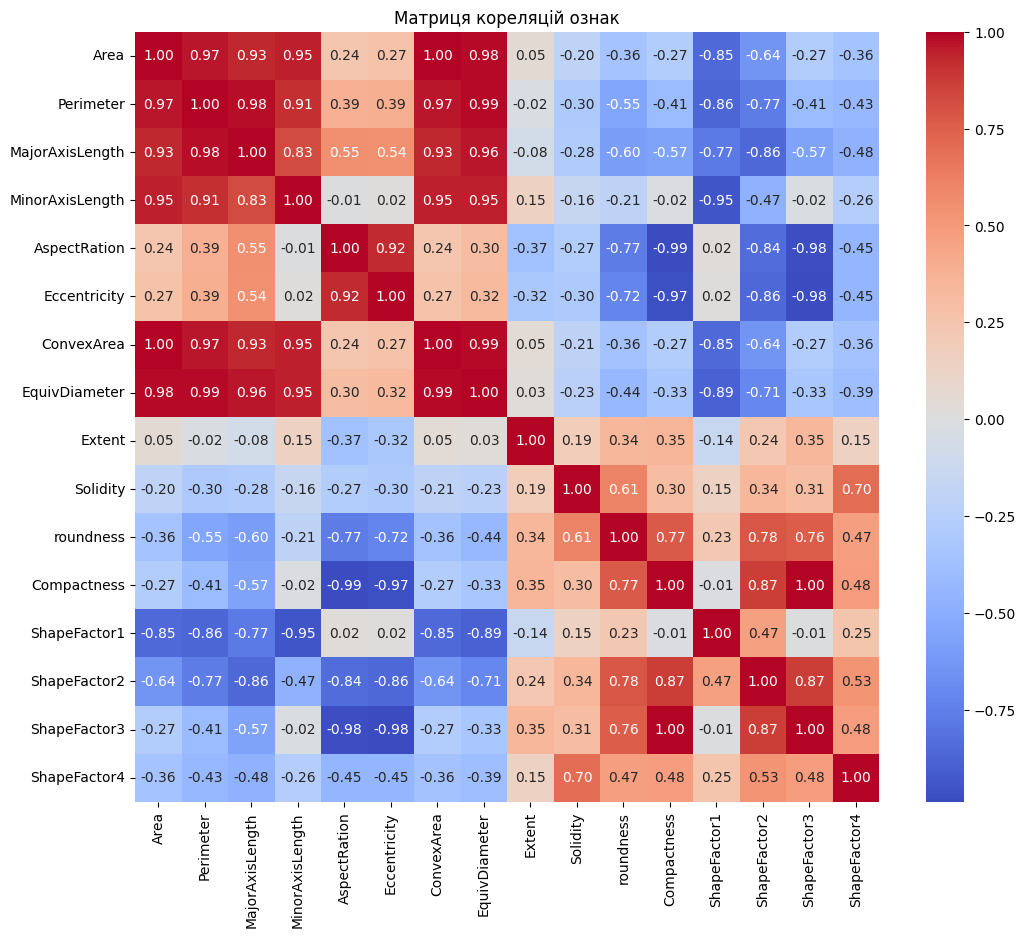

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, log_loss, confusion_matrix, ConfusionMatrixDisplay

# Завантаження даних
df = pd.read_excel('Dry_Bean_Dataset.xlsx')

# Аналіз кореляцій
plt.figure(figsize=(12, 10))
corr_matrix = df.drop('Class', axis=1).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Матриця кореляцій ознак")
plt.show()

# видалити ті ознаки, що мають кореляцію > 0.9 з іншими (Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,
# ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4)
# видалено Perimeter, ConvexArea, EquivDiameter, ShapeFactor2, ShapeFactor3
selected_features = [
    'Area', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 
    'Eccentricity', 'Extent', 'Solidity', 'roundness', 'ShapeFactor1', 'ShapeFactor4'
]

X = df[selected_features].values
y_labels = df['Class'].values

# Кодування цільової змінної 
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_labels)

# One-Hot Encoding для цільової змінної 
num_classes = len(np.unique(y_encoded))
Y_onehot = np.eye(num_classes)[y_encoded]

# Розбиття вибірки
# Global Test: 20%
X_temp, X_test, y_temp, y_test = train_test_split(X, Y_onehot, test_size=0.2, stratify=Y_onehot, random_state=42)

# Розбиття залишку на Global Validation (15% від загального) та FL Train Pool
# 0.15 / 0.80 = 0.1875
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1875, stratify=y_temp, random_state=42)

# Масштабування ознак
scaler = StandardScaler()
# тільки на тренувальних даних для запобігання Data Leakage
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

**Відбір ознак та мультиколінеарність:**
У датасеті Dry Bean більшість ознак описують геометрію зерна. Деякі з них математично виводяться одна з одної.
Наприклад, Area (площа), ConvexArea (опукла площа) та EquivDiameter (еквівалентний діаметр) мають кореляцію близьку до 1.0.
Якщо їх всіх залишити то це призведе до мультиколінеарності, що робить ваги моделі нестабільними.
Обрано базові виміри (Area, MajorAxisLength, MinorAxisLength), метрики форми (Extent, Solidity, roundness) та один/два ShapeFactor, а висококорельовані дублікати видалено.
    
Питання: чому розбиття даних потрiбно виконувати до масштабування, кодування або iнши операцiй, якi навчаються на даних? Пояснiть термiн Data Leakage.
    Розбиття даних потрібно виконувати до масштабування, щоб уникнути Data Leakage (витоку даних). 
    Якщо масштабувати весь датасет одразу, параметри масштабування (середнє значення та дисперсія) врахують інформацію з валідаційної та тестової вибірок.
    Це призведе до того, що модель матиме доступ до тестових даних під час навчання, і фінальні метрики якості будуть завищені та не точні.

4. **Кодування категоріальних ознак.**
Обрано спосіб кодування: `One-Hot Encoding`
Для коректної роботи функції та обчислення градієнтів, цільова змінна Y повинна мати формат матриці розмірністю m*C, що складається зі значень {0, 1}.
Саме такий формат дозволяє обчислювати функцію втрат, де ймовірність множиться на індикатор правильного класу Y. 
Використання Ordinal Encoding у цьому випадку створило б штучну ієрархію між незалежними сортами квасолі. 

5. **Масштабування**
Ознаки в датасеті мають кардинально різні діапазони значень (наприклад, площа Area вимірюється десятками тисяч, а Eccentricity знаходиться в межах від 0 до 1).
Стандартизація необхідна для надання всім ознакам однакової ваги та забезпечення стабільної збіжності градієнтного спуску.

### Етап 2. Реалiзацiя багатокласової логiстичної регресiї засобами numpy

In [6]:
class LogisticRegression:
    def __init__(self, n_features, n_classes, lr=0.01, lambda_reg=0.1):
        # lr (learning rate) швидкість навчання, визначає розмір кроку при оновленні ваг
        self.lr = lr
        # lambda_reg - коефіцієнт Ridge-регуляризації (L2), який штрафує занадто великі ваги
        self.lambda_reg = lambda_reg
        
        # Ініціалізація матриці ваг W нулями. 
        self.W = np.zeros((n_features, n_classes))  # кількість ознак × кількість класів
        
        # Ініціалізація вектора зсуву (bias) b нулями. 
        self.b = np.zeros((1, n_classes))  # 1 × кількість класів

    def softmax(self, Z):
        # Віднімання максимального значення в кожному рядку
        # запобігає переповненню (overflow) під час піднесення до експоненти (np.exp),
        # оскільки e^x для великих x може перевищити ліміти пам'яті
        Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z_shifted)
        
        # Нормалізація - ділення кожної експоненти на суму всіх експонент у рядку
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True) # матриця ймовірностей, де сума ймовірностей для кожного об'єкта дорівнює 1

    def predict_proba(self, X):
        # лінійна комбінація Z = X * W + b 
        Z = np.dot(X, self.W) + self.b
        return self.softmax(Z)  # Перетворення "сирих" значень на ймовірності

    def predict(self, X):
        # Отримання матриці ймовірностей для всіх класів
        P = self.predict_proba(X)
        # Вибір індексу класу (від 0 до n_classes-1) з найбільшою ймовірністю для кожного рядка (axis=1)
        return np.argmax(P, axis=1)

    def compute_loss(self, X, Y):
        # m - кількість об'єктів у вибірці X
        m = X.shape[0]
        P = self.predict_proba(X)  # отримання передбачених ймовірностей
        
        # Обмеження мінімального значення ймовірності до 1e-15
        epsilon = 1e-15
        P = np.clip(P, epsilon, 1 - epsilon)
        
        # Обчислення функції втрат (Cross-Entropy Loss) 
        cross_entropy = - (1 / m) * np.sum(Y * np.log(P))
        
        # Обчислення L2 (Ridge) штрафу (lambda / 2) * сума квадратів усіх ваг W
        l2_penalty = (self.lambda_reg / 2) * np.sum(self.W ** 2)
        
        # Загальна функція втрат = Крос-ентропія + Регуляризація
        return cross_entropy + l2_penalty

    def update_weights(self, X, Y):
        m = X.shape[0]
        P = self.predict_proba(X)
        
        # Обчислення градієнта для матриці ваг W
        dW = (1 / m) * np.dot(X.T, (P - Y)) + self.lambda_reg * self.W  # + self.lambda_reg * self.W похідна від L2-регуляризації
        
        # Обчислення градієнта для вектора зсуву b знаходить середню помилку по всіх прикладах (axis=0)
        db = (1 / m) * np.sum(P - Y, axis=0, keepdims=True)
        
        # Крок градієнтного спуску: оновлення параметрів у напрямку, протилежному до градієнта
        self.W -= self.lr * dW
        self.b -= self.lr * db
        
    def fit(self, X, Y, epochs=100, batch_size=32):
        m = X.shape[0]
        # Список для зберігання історії функції втрат
        losses = []
      
        for epoch in range(epochs):
# на початку кожної епохи випадковим чином переміщує індекси даних що допомагає алгоритму не зациклюватися
            indices = np.random.permutation(m)
            X_shuffled = X[indices]
            Y_shuffled = Y[indices]
            
            # розбиття перемішаного датасету на міні-батчі (mini-batches) заданого розміру
            for i in range(0, m, batch_size):
                # виділяє поточний батч
                X_batch = X_shuffled[i:i+batch_size]
                Y_batch = Y_shuffled[i:i+batch_size]
                # оновлення ваг тільки на основі цього батчу
                self.update_weights(X_batch, Y_batch)
                
# обчислює та зберігає загальний loss на всьому датасеті
            losses.append(self.compute_loss(X, Y))
            
        return losses

### Етап 3. Центрально навчана базова модель
Навчання логістичної регресії на всіх доступних тренувальних даних централізовано (`FL Train Pool`). 
Використано `Global Validation` для підбору гіперпараметрів (швидкість навчання, розмір батчу, параметр Ridge-регуляризації), а фінальну оцінку проведено виключно на `Global Test`.

Підбір гіперпараметрів на Global Validation
LR: 0.1, Lambda: 0.01 -> Val Accuracy: 0.9187
LR: 0.1, Lambda: 0.1 -> Val Accuracy: 0.8643
LR: 0.01, Lambda: 0.01 -> Val Accuracy: 0.9192
LR: 0.01, Lambda: 0.1 -> Val Accuracy: 0.8717

Найкращі гіперпараметри: {'lr': 0.01, 'lambda_reg': 0.01}


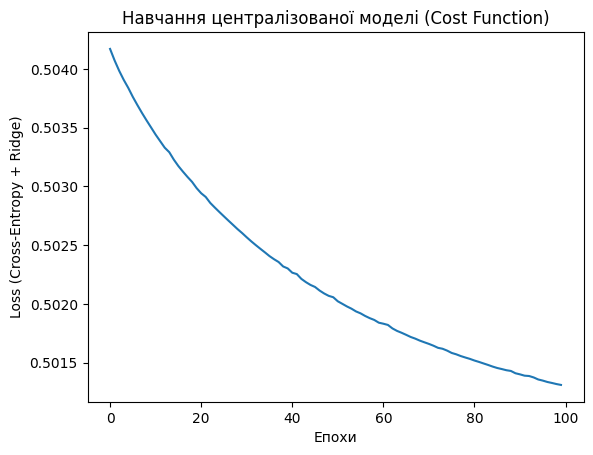

Оцінка централізованої моделі на Global Test
Accuracy: 0.9181
Macro-F1: 0.9293
Balanced Accuracy: 0.9282
Log-loss: 0.3711


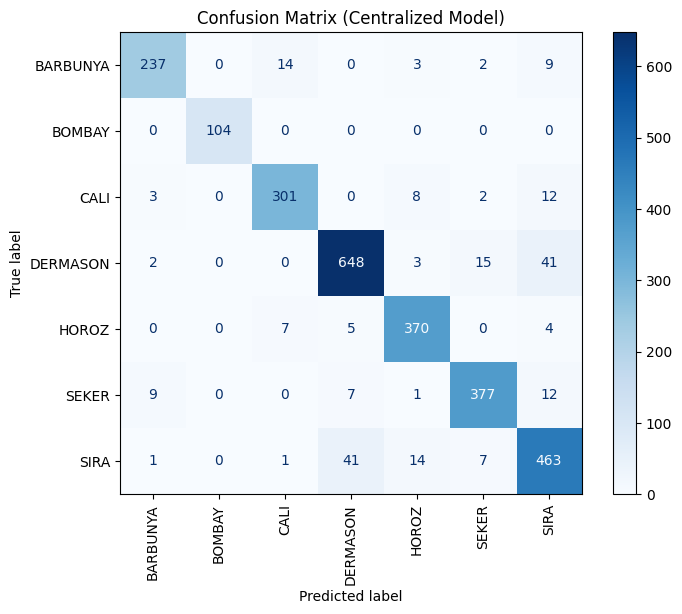

In [7]:
# пошук гіперпараметрів (Grid Search) на Global Validation
learning_rates = [0.1, 0.01]
lambda_regs = [0.01, 0.1]
best_val_acc = 0
best_params = {}
best_central_model = None

# отримання реальних міток класів для валідації 
y_val_labels = np.argmax(y_val, axis=1)

print("Підбір гіперпараметрів на Global Validation")
for lr in learning_rates:
    for reg in lambda_regs:
        # Ініціалізація моделі
        model = LogisticRegression(n_features=X_train_scaled.shape[1], 
                                         n_classes=y_train.shape[1], 
                                         lr=lr, lambda_reg=reg)
        
        # Навчання на FL Train Pool 
        model.fit(X_train_scaled, y_train, epochs=50, batch_size=32)
        
        # Оцінка на Global Validation
        val_preds = model.predict(X_val_scaled)
        val_acc = np.mean(val_preds == y_val_labels)
        print(f"LR: {lr}, Lambda: {reg} -> Val Accuracy: {val_acc:.4f}")
        
        # Збереження найкращої моделі
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_params = {'lr': lr, 'lambda_reg': reg}
            best_central_model = model

print(f"\nНайкращі гіперпараметри: {best_params}")

# Графік падіння функції втрат для найкращої моделі
plt.plot(best_central_model.fit(X_train_scaled, y_train, epochs=100, batch_size=32))
plt.title('Навчання централізованої моделі (Cost Function)')
plt.xlabel('Епохи')
plt.ylabel('Loss (Cross-Entropy + Ridge)')
plt.show()

# Отримання передбачення та реальні мітки для Global Test
y_test_labels = np.argmax(y_test, axis=1) # Справжні класи
test_preds = best_central_model.predict(X_test_scaled) # Передбачені класи
test_preds_proba = best_central_model.predict_proba(X_test_scaled) # Ймовірності для log-loss

print ("=========================")
print("Оцінка централізованої моделі на Global Test")

# Accuracy (Точність)
acc = accuracy_score(y_test_labels, test_preds)
print(f"Accuracy: {acc:.4f}")

# Macro-F1 (Середній F1-score для всіх класів)
macro_f1 = f1_score(y_test_labels, test_preds, average='macro')
print(f"Macro-F1: {macro_f1:.4f}")

# Balanced Accuracy (Точність, збалансована за розміром класів)
bal_acc = balanced_accuracy_score(y_test_labels, test_preds)
print(f"Balanced Accuracy: {bal_acc:.4f}")

# Log-loss (Крос-ентропія на тестовій вибірці)
lloss = log_loss(y_test, test_preds_proba)
print(f"Log-loss: {lloss:.4f}")

# Confusion Matrix (Матриця плутанини)
cm = confusion_matrix(y_test_labels, test_preds)

plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=encoder.classes_)
disp.plot(cmap='Blues', ax=plt.gca(), xticks_rotation='vertical')
plt.title('Confusion Matrix (Centralized Model)')
plt.show()

**Гіперпараметри:** Використання `Global Validation` дозволило обрати найкращу комбінацію швидкості навчання та Ridge-регуляризації. Регуляризація допомогла уникнути перенавчання.
**Метрики якості:** `Macro-F1` та `Balanced Accuracy` є критично важливими метриками для цього датасету, оскільки класи сортів квасолі можуть бути незбалансованими за кількістю прикладів. Якщо звичайна `Accuracy` висока, але `Macro-F1` значно нижча — це означало б, що модель погано розпізнає міноритарні класи.
**Матриця плутанини:** Показує, які саме класи сортів квасолі модель плутає між собою найчастіше (візуально це темні квадрати поза головною діагоналлю).

### Етап 4. Розподiл даних мiж клiєнтами та сервером

In [8]:
def create_clients_data(X, y_onehot, num_clients=5, alpha=1.0, is_iid=True):
    # Створює словник, де ключами є ID клієнтів (від 0 до 4), 
    # а значеннями — порожні списки для ознак ('X') та міток ('y')
    client_data = {i: {'X': [], 'y': []} for i in range(num_clients)}
    
    # Перетворюємо One-Hot мітки назад у звичайні індекси класів ( з [0,0,1] у 2).
    y_labels = np.argmax(y_onehot, axis=1)
    num_classes = y_onehot.shape[1]
    
    if is_iid:
        # IID розподіл перемішує та ділить порівну
        
        # Генерує випадкову послідовність індексів від 0 до загальної кількості зразків
        indices = np.random.permutation(len(X))
        
        # Розбиває масив індексів на рівні (або майже рівні) частини за кількістю клієнтів
        splits = np.array_split(indices, num_clients)
        
        # Призначає кожному клієнту його частину перемішаних даних
        for i in range(num_clients):
            client_data[i]['X'] = X[splits[i]]
            client_data[i]['y'] = y_onehot[splits[i]]
            
    else:
        # Non-IID розподіл 
        min_size = 0   
        # Цикл працює, поки не знайдеться розподіл, де кожний клієнт отримає хоча б 10 зразків
        while min_size < 10: 
            # Ініціалізує порожні списки індексів для кожного клієнта на поточну ітерацію
            idx_batch = [[] for _ in range(num_clients)]

            for k in range(num_classes):
                # Знаходить всі індекси зразків які належать до поточного класу 'k'
                idx_k = np.where(y_labels == k)[0]
                np.random.shuffle(idx_k) # Перемішує ці індекси
                
                # Якщо alpha мале (0.3), один клієнт може отримати 90% цього класу, а інші — по 1-2%.
                proportions = np.random.dirichlet(np.repeat(alpha, num_clients))
                
                # Якщо клієнт вже зібрав забагато даних, 
                # його пропорція для цього класу обнуляється, щоб він не забрав усі дані.
                proportions = np.array([p * (len(idx_j) < len(X) / num_clients) for p, idx_j in zip(proportions, idx_batch)])
                
                # Нормалізує пропорції, щоб їхня сума знову дорівнювала 1 
                proportions = proportions / proportions.sum()
                
                # Конвертує відсоткові пропорції у конкретні індекси розбиття масиву.
                # np.cumsum додає їх накопичувально, а множення на len(idx_k) дає кількість елементів.
                proportions = (np.cumsum(proportions) * len(idx_k)).astype(int)[:-1]
                
                # Розбиває індекси поточного класу на частини (np.split)
                idx_batch = [idx_j + idx.tolist() for idx_j, idx in zip(idx_batch, np.split(idx_k, proportions))]
                
            # Перевіряє розмір найменшого пулу даних серед усіх клієнтів
            min_size = min([len(idx_j) for idx_j in idx_batch])
            
        # Після успішного знаходження індексів, формує фінальні матриці X та Y для кожного клієнта
        for i in range(num_clients):
            client_data[i]['X'] = X[idx_batch[i]]
            client_data[i]['y'] = y_onehot[idx_batch[i]]
            
    return client_data

# Створює словник clients_non_iid, де дані розбиті на 5 частин 
clients_non_iid = create_clients_data(X_train_scaled, y_train, num_clients=5, alpha=0.3, is_iid=False)

### Етап 5. Симуляцiя  федеративного навчання 

In [9]:
import copy

def fed_avg_simulation(client_data, X_val, y_val, num_rounds=20, local_epochs=5):
    n_features = X_val.shape[1]
    n_classes = y_val.shape[1]
   
    global_model = LogisticRegression(n_features, n_classes, lr=0.1)
    
    val_accuracy_history = []
    
    for round_num in range(num_rounds):
        local_weights_W = []
        local_weights_b = []
        data_sizes = []
        
        # Навчання на клієнтах
        for client_id, data in client_data.items():
            local_model = LogisticRegression(n_features, n_classes, lr=0.1)
            # Копіює глобальні ваги на клієнт
            local_model.W = copy.deepcopy(global_model.W)
            local_model.b = copy.deepcopy(global_model.b)
            
            # Локальне навчання
            local_model.fit(data['X'], data['y'], epochs=local_epochs)
            
            local_weights_W.append(local_model.W)
            local_weights_b.append(local_model.b)
            data_sizes.append(len(data['X']))
            
        #Агрегація ваг на сервері 
        total_data = sum(data_sizes)
        
        # Зважене середнє
        new_W = np.zeros_like(global_model.W)
        new_b = np.zeros_like(global_model.b)
        
        for i in range(len(client_data)):
            weight = data_sizes[i] / total_data
            new_W += weight * local_weights_W[i]
            new_b += weight * local_weights_b[i]
            
        global_model.W = new_W
        global_model.b = new_b
        
        # Оцінка на Global Validation
        preds = global_model.predict(X_val)
        y_true = np.argmax(y_val, axis=1)
        acc = np.mean(preds == y_true)
        val_accuracy_history.append(acc)
        print(f"Round {round_num+1} - Validation Accuracy: {acc:.4f}")
        
    return global_model, val_accuracy_history

# Запуск симуляції
final_global_model, history = fed_avg_simulation(clients_non_iid, X_val_scaled, y_val, num_rounds=20, local_epochs=5)

Round 1 - Validation Accuracy: 0.6278
Round 2 - Validation Accuracy: 0.6117
Round 3 - Validation Accuracy: 0.6072
Round 4 - Validation Accuracy: 0.6063
Round 5 - Validation Accuracy: 0.6004
Round 6 - Validation Accuracy: 0.6063
Round 7 - Validation Accuracy: 0.6053
Round 8 - Validation Accuracy: 0.5926
Round 9 - Validation Accuracy: 0.5960
Round 10 - Validation Accuracy: 0.5935
Round 11 - Validation Accuracy: 0.6024
Round 12 - Validation Accuracy: 0.5984
Round 13 - Validation Accuracy: 0.6053
Round 14 - Validation Accuracy: 0.6004
Round 15 - Validation Accuracy: 0.6058
Round 16 - Validation Accuracy: 0.6033
Round 17 - Validation Accuracy: 0.5984
Round 18 - Validation Accuracy: 0.6009
Round 19 - Validation Accuracy: 0.6068
Round 20 - Validation Accuracy: 0.6033


Питання: чому ваги клiєнтiв доцiльно зважувати за кiлькiстю прикладiв? Що станеться, якщо використовувати просте середнє без зважування?
Ваги доцільно зважувати за кількістю прикладів, оскільки клієнт з більшою кількістю даних має більш точну оцінку градієнтів глобальної цільової функції. Якщо використовувати просте середнє, клієнт з 10 прикладами матиме такий самий вплив, як клієнт з 10 000 прикладів, що призведе до сильного зміщення моделі та падіння якості.

### Етап 6. Дослiдження ефектiв федеративного навчання 

In [10]:
def evaluate_model(model, X_test, y_test_onehot):
    y_true = np.argmax(y_test_onehot, axis=1)
    preds = model.predict(X_test)
    preds_proba = model.predict_proba(X_test)
    
    acc = accuracy_score(y_true, preds)
    f1 = f1_score(y_true, preds, average='macro')
    bal_acc = balanced_accuracy_score(y_true, preds)
    lloss = log_loss(y_test_onehot, preds_proba)
    
    return [acc, f1, bal_acc, lloss]

# Навчання локальної моделі 
client_0_data = clients_non_iid[0]
local_model = LogisticRegression(n_features=X_train_scaled.shape[1], n_classes=y_train.shape[1], lr=0.1)
local_model.fit(client_0_data['X'], client_0_data['y'], epochs=50)

metrics_local = evaluate_model(local_model, X_test_scaled, y_test)
metrics_global = evaluate_model(final_global_model, X_test_scaled, y_test)
metrics_central = evaluate_model(best_central_model, X_test_scaled, y_test)

# Формування таблиці
results_df = pd.DataFrame([metrics_local, metrics_global, metrics_central],
                          columns=['Accuracy', 'Macro-F1', 'Balanced Accuracy', 'Log-Loss'],
                          index=['Local Model (Client 0)', 'Global Model (FedAvg)', 'Centralized Model'])

print("Порівняння моделей на Global Test")
display(results_df)

Порівняння моделей на Global Test


,Accuracy,Macro-F1,Balanced Accuracy,Log-Loss
Local Model (Client 0),0.435549,0.339730,0.432008,2.849623
Global Model (FedAvg),0.599706,0.542025,0.604074,1.150494
Centralized Model,0.918105,0.929327,0.928185,0.371069


### Експеримент 1. Вплив неоднорідності даних
Параметр розподілу Діріхле ($\alpha$) впливає на якість федеративного навчання. 
* $\alpha = 5$ (дані майже однорідні, близькі до IID).
* $\alpha = 1$ (помірна неоднорідність).
* $\alpha = 0.3$ (сильна неоднорідність, у клієнтів бракує певних класів).


Симуляція для alpha = 5
Round 1 - Validation Accuracy: 0.8555
Round 2 - Validation Accuracy: 0.8643
Round 3 - Validation Accuracy: 0.8526
Round 4 - Validation Accuracy: 0.8604
Round 5 - Validation Accuracy: 0.8678
Round 6 - Validation Accuracy: 0.8580
Round 7 - Validation Accuracy: 0.8590
Round 8 - Validation Accuracy: 0.8531
Round 9 - Validation Accuracy: 0.8590
Round 10 - Validation Accuracy: 0.8599
Round 11 - Validation Accuracy: 0.8595
Round 12 - Validation Accuracy: 0.8560
Round 13 - Validation Accuracy: 0.8590
Round 14 - Validation Accuracy: 0.8619
Round 15 - Validation Accuracy: 0.8516
Round 16 - Validation Accuracy: 0.8604
Round 17 - Validation Accuracy: 0.8624
Round 18 - Validation Accuracy: 0.8546
Round 19 - Validation Accuracy: 0.8604
Round 20 - Validation Accuracy: 0.8575

Симуляція для alpha = 1
Round 1 - Validation Accuracy: 0.7502
Round 2 - Validation Accuracy: 0.7414
Round 3 - Validation Accuracy: 0.7409
Round 4 - Validation Accuracy: 0.7453
Round 5 - Validation Accura

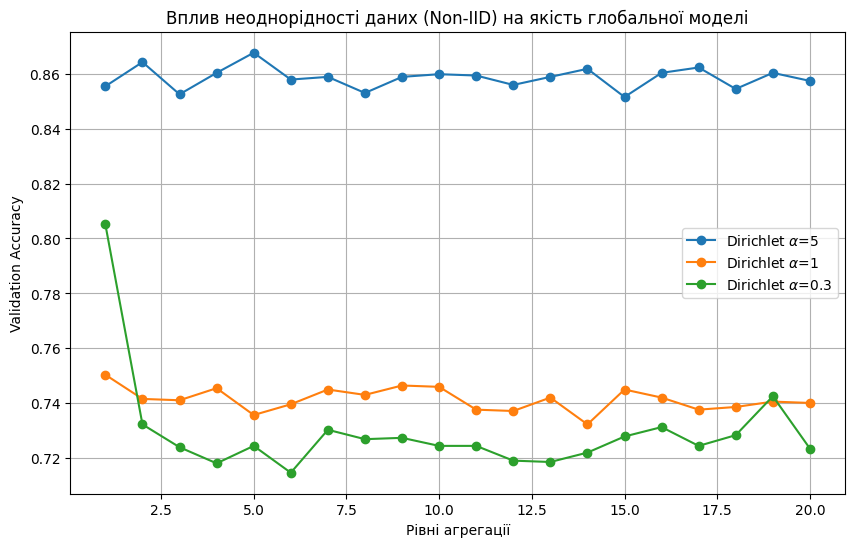

In [11]:
alphas = [5, 1, 0.3]
alpha_results = {}

for alpha in alphas:
    print(f"\nСимуляція для alpha = {alpha}")
    # Створення розподілу даних для поточного альфа
    clients_data = create_clients_data(X_train_scaled, y_train, num_clients=5, alpha=alpha, is_iid=False)
    
    _, history = fed_avg_simulation(clients_data, X_val_scaled, y_val, num_rounds=20, local_epochs=5)
    alpha_results[alpha] = history

# Побудова графіка
plt.figure(figsize=(10, 6))
for alpha, history in alpha_results.items():
    plt.plot(range(1, 21), history, label=f'Dirichlet $\\alpha$={alpha}', marker='o')

plt.title('Вплив неоднорідності даних (Non-IID) на якість глобальної моделі')
plt.xlabel('Рівні агрегації')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

**Аналіз результатів Експерименту 1:**
**Чому Non-IID дані погіршують федеративне навчання:** У сильно неоднорідному середовищі ($\alpha = 0.3$) кожен клієнт бачить лише підмножину класів. Локальні моделі швидко оптимізуються під специфічний набір даних (перенавчаються на своїх класах). При агрегації цих сильно розбіжних ваг на сервері, усереднена глобальна модель втрачає інформацію і "забуває" класи, працюючи гірше.
**Чи може глобальна модель бути гіршою за централізовану:** Так, глобальна модель майже завжди трохи гірша або дорівнює централізованій. Централізована модель бачить усі дані разом і може коректно оцінити глобальні градієнти, тоді як FedAvg є наближенням, яке страждає від відхилень ваг у Non-IID умовах.
**Чи може глобальна модель бути гіршою за деякі локальні:** Так. Якщо локальна тестова вибірка клієнта має такий самий специфічний (спотворений) розподіл, як і його тренувальні дані, то його вузькоспеціалізована локальна модель покаже на цих даних кращий результат, ніж узагальнена глобальна модель.

### Експеримент 2. Вплив кількості локальних епох
Фіксування сильної неоднорідності ($\alpha = 0.3$) і дослідження впливу кількості локальних епох (E = 1, 5, 10).


Симуляція для E = 1 локальних епох
Round 1 - Validation Accuracy: 0.6087
Round 2 - Validation Accuracy: 0.6543
Round 3 - Validation Accuracy: 0.6641
Round 4 - Validation Accuracy: 0.6650
Round 5 - Validation Accuracy: 0.6572
Round 6 - Validation Accuracy: 0.6445
Round 7 - Validation Accuracy: 0.6357
Round 8 - Validation Accuracy: 0.6298
Round 9 - Validation Accuracy: 0.6391
Round 10 - Validation Accuracy: 0.6332
Round 11 - Validation Accuracy: 0.6298
Round 12 - Validation Accuracy: 0.6263
Round 13 - Validation Accuracy: 0.6219
Round 14 - Validation Accuracy: 0.6224
Round 15 - Validation Accuracy: 0.6293
Round 16 - Validation Accuracy: 0.6303
Round 17 - Validation Accuracy: 0.5989
Round 18 - Validation Accuracy: 0.6244
Round 19 - Validation Accuracy: 0.6347
Round 20 - Validation Accuracy: 0.6205

Симуляція для E = 5 локальних епох
Round 1 - Validation Accuracy: 0.5495
Round 2 - Validation Accuracy: 0.5661
Round 3 - Validation Accuracy: 0.5377
Round 4 - Validation Accuracy: 0.5299
Round

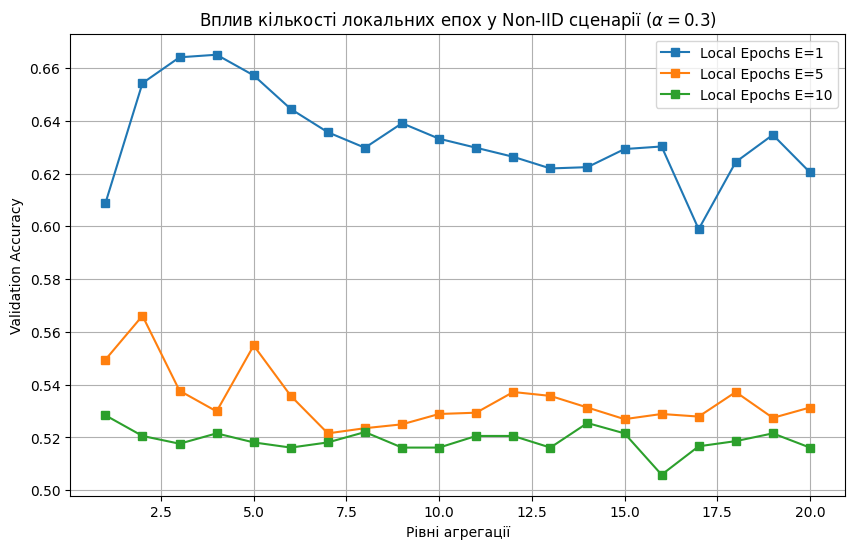

In [12]:
epochs_list = [1, 5, 10]
epoch_results = {}

# Використовує єдиний Non-IID розподіл для порівняння
clients_data_epoch_test = create_clients_data(X_train_scaled, y_train, num_clients=5, alpha=0.3, is_iid=False)

for E in epochs_list:
    print(f"\nСимуляція для E = {E} локальних епох")
    _, history = fed_avg_simulation(clients_data_epoch_test, X_val_scaled, y_val, num_rounds=20, local_epochs=E)
    epoch_results[E] = history

# Побудова графіка
plt.figure(figsize=(10, 6))
for E, history in epoch_results.items():
    plt.plot(range(1, 21), history, label=f'Local Epochs E={E}', marker='s')

plt.title('Вплив кількості локальних епох у Non-IID сценарії ($\\alpha=0.3$)')
plt.xlabel('Рівні агрегації')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

**Аналіз результатів Експерименту 2:**
**Що таке Client Drift (клієнтський дрейф):** Це явище у федеративному навчанні, коли локальні моделі клієнтів у процесі навчання починають надто сильно розходитися в різних напрямках у просторі параметрів (через різницю у своїх локальних даних).
**Вплив великої кількості епох:** У сценарії IID збільшення локальних епох прискорює збіжність. Але в Non-IID сценарії ($\alpha=0.3$) велика кількість локальних епох (наприклад, $E=10$) **погіршує** глобальну модель. За 10 епох локальна модель встигає повністю підлаштуватися під свій специфічний набір класів, "забувши" початковий глобальний стан. Коли сервер усереднює ці кардинально різні ваги, він отримує нестабільну і неякісну глобальну модель. Менша кількість епох ($E=1$) не дає вагам надто сильно відхилитися від глобального консенсусу.

1. Чому для багатокласової класифікації використовують softmax?
Softmax перетворює сирі значення, отримані з лінійної частини моделі, на вектор ймовірностей. Завдяки експоненційній функції всі значення стають додатними, а їхня сума завжди дорівнює 1, що дозволяє інтерпретувати вихід як ймовірність належності об'єкта до кожного з класів.
2. Чому крос-ентропія є природною функцією втрат для логістичної регресії?
Крос-ентропія вимірює розбіжність між двома розподілами ймовірностей: істинним (де правильний клас має ймовірність 1, а інші 0) та передбаченим моделлю (результат softmax). Вона сильно штрафує модель за впевнені, але хибні передбачення, забезпечуючи стабільні та ненульові градієнти під час навчання.
3. Чим відрізняється Ridge-регуляризація від Lasso-регуляризації?
Ridge (L2-регуляризація) додає до функції втрат штраф у вигляді суми квадратів ваг, що змушує ваги моделі бути рівномірно малими, запобігаючи домінуванню окремих ознак. Lasso (L1-регуляризація) додає штраф у вигляді суми модулів ваг, що призводить до занулення частини ваг і працює як вбудований метод відбору ознак (робить модель розрідженою).
4. Чому параметр зміщення (b) зазвичай не регуляризують?
Параметр зміщення дозволяє моделі адаптуватися до базового розподілу цільової змінної (змістити площину прийняття рішень від початку координат). Його регуляризація штучно змушувала б модель проходити через початок координат (0,0), що часто не відповідає реальній природі даних і погіршує якість апроксимації.
5. Що таке Data Leakage?
Data Leakage (витік даних) — це ситуація, коли під час навчання моделі випадково або помилково використовується інформація, яка має бути доступною лише на етапі тестування. Це призводить до штучно завищених метрик, але модель провалюється на реальних нових даних.
6. Чому тестову вибірку не можна використовувати для підбору гіперпараметрів?
Якщо підбирати гіперпараметри на тестовій вибірці, модель побічно "завчить" особливості цих даних. Тестова вибірка втратить статус незалежного мірила якості, а фінальна оцінка буде упередженою і не відображатиме реальної здатності моделі до узагальнення.
7. Чому параметри масштабування потрібно навчати лише на тренувальних даних?
Щоб уникнути Data Leakage. Якщо обчислити середнє значення або дисперсію для масштабування на всьому датасеті одразу, статистичні характеристики валідаційної та тестової вибірок вплинуть на тренувальні дані.
8. Що таке федеративне навчання і які його основні переваги?
Федеративне навчання — це децентралізований підхід, де локальні моделі навчаються на пристроях клієнтів, а центральний сервер лише агрегує їхні параметри (ваги), не маючи доступу до самих даних. Основні переваги: забезпечення конфіденційності (privacy) користувацьких даних, зниження навантаження на мережу (не треба передавати гігабайти даних) та використання локальних обчислювальних ресурсів клієнтів.
9. Чому сервер не повинен отримувати сирі дані клієнтів?
Це порушує головний принцип федеративного навчання — збереження приватності та безпеки даних користувачів. Сервер повинен бачити лише оновлені параметри моделей.
10. Чому агрегація ваг за методом FedAvg використовує зважування за кількістю прикладів?
Клієнти з більшою кількістю тренувальних прикладів (наприклад, 10 000) генерують більш статистично значущі та точні градієнти. Зважування дозволяє їм мати пропорційно більший вплив на формування глобальної моделі.
11. Що станеться, якщо агрегувати параметри клієнтів без зважування?
Просте усереднення надасть однакового впливу як клієнту з 10 прикладами, так і клієнту зі 100 000 прикладів. Модель від клієнта з малою кількістю даних може бути сильно перенавченою або містити шум, що критично спотворить і погіршить фінальну глобальну модель.
12. Що таке Non-IID дані?
Non-IID (Non-Independent and Identically Distributed) означає, що дані на різних клієнтах розподілені нерівномірно та неоднорідно. Наприклад, в одного клієнта можуть переважати фотографії лише певного класу, який взагалі відсутній в інших клієнтів.
13. Чому федеративне навчання може погіршуватися на Non-IID даних?
Локальні моделі сильно оптимізуються під свої вузькі набори класів. При їхній агрегації на сервері виникає конфлікт: усереднення абсолютно різних за напрямком оптимізації ваг призводить до втрати знань та загального падіння якості узагальненої глобальної моделі.
14. Що таке клієнтський дрейф (client drift)?
Це надмірне відхилення локальних моделей клієнтів від глобальної моделі в процесі локального навчання. Локальні ваги "дрейфують" у напрямку локального оптимуму (своїх специфічних Non-IID даних), що ускладнює їхню успішну агрегацію на сервері.
15. Як кількість локальних епох впливає на глобальну модель?
Для однорідних даних збільшення локальних епох прискорює збіжність. Однак у випадку Non-IID даних велика кількість локальних епох посилює клієнтський дрейф: локальні моделі занадто перенавчаються під свою вибірку, що суттєво погіршує якість об'єднаної глобальної моделі.
16. Чи може глобальна модель бути гіршою за централізовану модель? Чому?
Так, найчастіше глобальна модель працює трохи або суттєво гірше. Централізована модель одночасно бачить усі дані (повний FL Train Pool), обчислюючи точний градієнт для всього масиву. Глобальна модель агрегує наближення, і через клієнтський дрейф (особливо на Non-IID даних) ці наближення не є ідеальними.
17. Які метрики краще використовувати для багатокласової класифікації з можливим дисбалансом класів?
Замість звичайної Accuracy слід використовувати Macro-F1 та Balanced Accuracy. Ці метрики обчислюють якість окремо для кожного класу і знаходять незважене середнє значення, що гарантує рівноцінний вплив усіх класів (навіть міноритарних) на фінальну оцінку. 